X_train 形状: torch.Size([115058, 24, 1])
y_train 形状: torch.Size([115058, 1])
VoltageLSTM(
  (lstm): LSTM(1, 48, num_layers=2, batch_first=True)
  (fc): Linear(in_features=48, out_features=1, bias=True)
)
Epoch [10/15], Loss: 0.214288


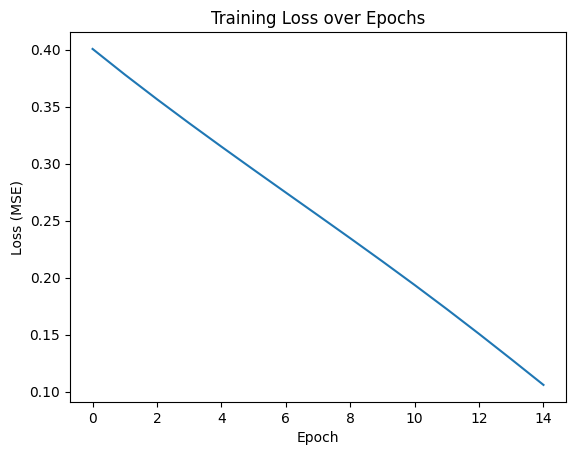

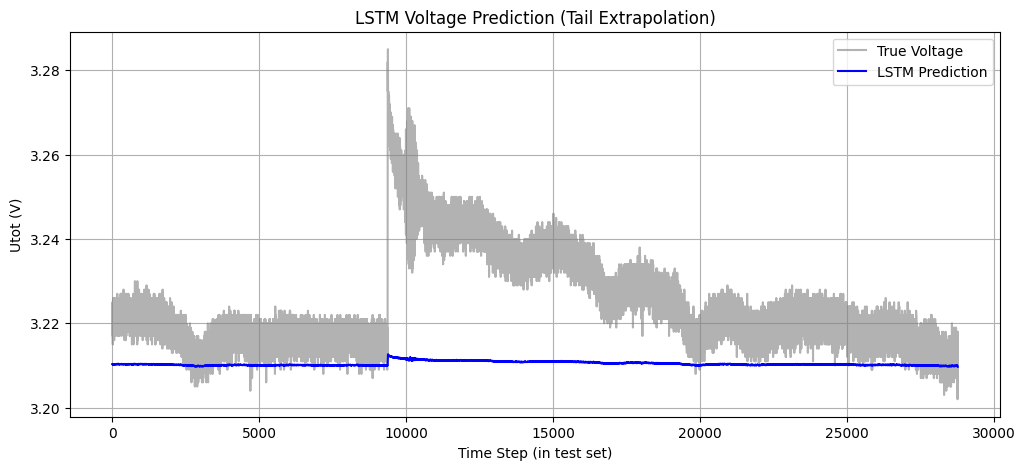

LSTM 测试集 RMSE: 0.018054 V


In [1]:
#初代LSTM
import numpy as np
import pandas as pd
import torch#它会用GPU，有自动求导机制，模型内部有无数个旋钮（参数）。自动求导（Autograd）就像是一个“找方向仪”。它通过微积分里的“链式法则”，自动算出：“如果我调高A旋钮，误差是变大还是变小？调低B旋钮，误差会怎么变？”
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler#（归一化），否则“梯度爆炸”
import matplotlib.pyplot as plt
#算完之后，优化器（Optimizer）就会顺着“误差变小的方向”去拧这些旋钮。这就是模型学习的本质。

file_path = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1.csv'
df = pd.read_csv(file_path)
data = df['Utot (V)'].values.reshape(-1, 1)
#加上.values可以把这列数据剥掉“Excel外衣”，变成纯纯的 NumPy 数组（类似于 [3.3, 3.31, 3.29...]）。神经网络不认 pandas 格式，只认纯数字数组。
#变成 (-1, 1) 的意思是：变成 1 列，行数让电脑自己算（-1 就代表自动推算）。

scaler = MinMaxScaler(feature_range=(0, 1))#scaler：归一化
#这行代码只是定义了这个“0~1”压缩工具，还没有真正去压缩数据。
data_scaled = scaler.fit_transform(data)#之所以叫_scaled，只是为了方便程序员看懂
#scaler归一化；fit：计算数据的最大值和最小值；transform：把所有数字套进公式 (当前值 - 最小值) / (最大值 - 最小值)。.fit_transform成套工具箱

# 3. 构建滑动窗口（核心逻辑！）
def create_sequences(data, seq_length):#假设数据是：[10, 20, 30, 40, 50, 60]，seq_length = 3（用过去 3 个预测第 4 个）。
    xs = []
    ys = []
    for i in range(len(data) - seq_length):
        # x 是过去 seq_length 天的数据
        x = data[i : i + seq_length]#默认左闭右开
        # y 是紧接着的下一天的数据
        y = data[i + seq_length]
        xs.append(x)#.append() 就是“插队到最后一个”。
        ys.append(y)
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 24 #seq_length步长，用seq_length去预测下一个点
X_lstm, y_lstm = create_sequences(data_scaled, SEQ_LENGTH)#create_sequences这个厨子拿着SEQ_LENGTH去划拉data_scaled，划拉的历史是X_lstm，划拉出的未来是y_lstm（一个）

# 4. 划分训练集和测试集（必须按时间顺序！80% 训练）
train_size = int(len(X_lstm) * 0.8)
X_train_lstm, X_test_lstm = X_lstm[:train_size], X_lstm[train_size:]
y_train_lstm, y_test_lstm = y_lstm[:train_size], y_lstm[train_size:]

# 5. 转成 PyTorch 专属的张量 (Tensor)
# LSTM 要求的形状：（样本，步长，特征）即(Batch_Size, Sequence_Length, Features)
X_train_tensor = torch.FloatTensor(X_train_lstm)
y_train_tensor = torch.FloatTensor(y_train_lstm)
X_test_tensor = torch.FloatTensor(X_test_lstm)
y_test_tensor = torch.FloatTensor(y_test_lstm)
#torch.FloatTensor张量转换：把 Numpy 数组（float性质）变成 PyTorch 能吃的、带小数的高精度张量（Tensor）矩阵。

print("X_train 形状:", X_train_tensor.shape) # 应该是 [52000多, 24, 1]
print("y_train 形状:", y_train_tensor.shape) # 应该是 [52000多, 1]

# 定义 LSTM 模型
class VoltageLSTM(nn.Module):# 定义一个名为 VoltageLSTM 的类，它继承自 nn.Module（这是 PyTorch 所有神经网络的祖师爷）
    def __init__(self, input_size=1, hidden_size=48, num_layers=2, output_size=1):# 必须加这一句，属于配置单
        super(VoltageLSTM, self).__init__()#super(...)：意思是去把PyTorch的nn.Module的初始化配置全盘继承过来。是极其固定的八股文
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)#self.lstm：告诉自己“给我装一个 LSTM 引擎”。
        # Batch（样本数/行），Seq（时间步长/列），Features（特征数）
        # batch_first=True 就是告诉 PyTorch，我给你的三维数据顺序是：[样本数, 时间步长, 特征数]。
        # batch_first=True 非常重要：告诉 PyTorch，我喂给你的数据，第 0 维是样本数(batch)，第 1 维是时间步(seq)
        # 2. 全连接层（把 LSTM 记住的东西，翻译成我们想要的 1 个预测数值）
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x 的形状是 (batch_size, seq_length, features)
        # out 包含了所有时间步的输出，_ 是隐藏状态（我们这里不需要用它）
        out, _ = self.lstm(x)

        # 我们只关心最后一个时间步（即第 24 个点）推导出来的结果
        # out[:, -1, :] 的意思就是取所有 batch 的最后一个序列的输出
        out = self.fc(out[:, -1, :])# out[:, -1, :] 这个切片的意思是：取所有行(:)，取最后一列时间步(-1)，取所有的特征(:)
        return out

# 实例化模型
model = VoltageLSTM()
print(model)

 # 1. 定义损失函数和优化器
criterion = nn.MSELoss() # 均方误差（之前我们讲过的那个）
# Adam 是最好用的优化器。lr=0.001 是学习率（步子迈多大）
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 2. 开始训练
epochs = 15 # 训练 50 轮
# 训练技巧：记录 loss，画图看它是不是在下降
loss_history = []

model.train() # 开启训练模式
for epoch in range(epochs):
    # 前向传播
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)

    # 反向传播（这三句是 PyTorch 的固定套路）
    optimizer.zero_grad() # 清空上一轮的梯度
    loss.backward()       # 根据误差，倒推责任
    optimizer.step()      # 更新模型参数

    loss_history.append(loss.item())

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.6f}')

# 画 Loss 曲线（如果曲线一路向下，说明模型学得很开心）
plt.plot(loss_history)
plt.title('Training Loss over Epochs')#Training Loss over Epochs:误差成绩下降曲线
plt.xlabel('Epoch')#Epochs（轮次）Loss（损失/误差）
plt.ylabel('Loss (MSE)')#横轴是学了第几遍，纵轴是误差。
plt.show()

# 1. 测试阶段
model.eval() # 开启测试模式
with torch.no_grad(): # 测试时不需要计算梯度，节省内存
    predictions = model(X_test_tensor)

# 2. 反归一化（我们之前把 3.3V 变成了 0.1，现在要变回来才能和真实值比）
predictions_real = scaler.inverse_transform(predictions.numpy())
y_test_real = scaler.inverse_transform(y_test_tensor.numpy())

# 3. 画图对比
plt.figure(figsize=(12, 5))
# 画真实的后 20% 数据
plt.plot(range(len(y_test_real)), y_test_real, label='True Voltage', color='gray', alpha=0.6)
# 画 LSTM 预测的数据
plt.plot(range(len(predictions_real)), predictions_real, label='LSTM Prediction', color='blue')
plt.xlabel('Time Step (in test set)')
plt.ylabel('Utot (V)')
plt.title('LSTM Voltage Prediction (Tail Extrapolation)')
plt.legend()
plt.grid(True)
#plt.savefig(r'C:\Users\YOGA\Desktop\神经学习v1', dpi=300, bbox_inches='tight')
plt.show()

# 算一下 RMSE
from sklearn.metrics import mean_squared_error
import math
rmse_lstm = math.sqrt(mean_squared_error(y_test_real, predictions_real))
print(f"LSTM 测试集 RMSE: {rmse_lstm:.6f} V")